# Projeto Final (P2) · Parafusos e porcas numa bancada
**EC01039 · PDI · Tema 6**

Integrantes:

**Problema:** contar quantos parafusos e quantas porcas tem numa foto da bancada. Serve pra quem faz inventário de peças (oficina, almoxarifado, montagem).

**O número que o sistema devolve:** quantidade de parafusos e quantidade de porcas.

**Aquisição:** peças sobre papel branco, foto com o celular. Tiramos 11 fotos variando a luz (ambiente, flash, luminária, pouca luz, sombra da mão) e o ângulo (de cima e inclinado), com dois conjuntos de peças: 7 parafusos + 4 porcas (fotos 1 a 5 e 11) e 9 parafusos + 7 porcas (fotos 6 a 10).

**Pipeline:**
cinza + redimensionar → suavizar (gaussiano 5×5) → dividir pelo fundo → limiar (Otsu, BINARY_INV) → abertura → fechamento → preencher furos → componentes conexos (N8) → filtro de área e de borda → classificar pela forma → contar

**Ordem que não pode trocar:**
- suavizar antes do limiar: o ruído e a textura do papel viram pontinhos na máscara se o limiar vier antes.
- dividir pelo fundo antes do limiar: o flash deixa o centro claro e os cantos escuros, e com um T só os cantos viram objeto.
- abertura antes do fechamento: se fechar primeiro, os pontinhos de ruído engordam e grudam nas peças.

**O que pode dar errado:** sombra forte (da mão ou da própria peça na foto inclinada) vira objeto, porca de plástico branca some no papel branco, peças encostadas viram um objeto só, brilho do metal quebra a peça em pedaços.

In [1]:
import numpy as np, cv2, matplotlib.pyplot as plt

def mostrar(*imgs, titulos=None, tam=5):
    fig, ax = plt.subplots(1, len(imgs), figsize=(tam*len(imgs), tam))
    ax = np.atleast_1d(ax)
    for i, im in enumerate(imgs):
        ax[i].imshow(im, cmap='gray'); ax[i].axis('off')
        if titulos: ax[i].set_title(titulos[i])
    plt.show()

def ee(k):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))

def n_objetos(m):
    return cv2.connectedComponents(m, connectivity=8)[0] - 1

## Fotos e referência manual


In [2]:
PASTA = 'fotos/'   # pasta com as fotos
fotos = [f'Foto_{i}_parafuso_porca.jpg' for i in range(1, 12)]

# referência manual
referencia = {
    'Foto_1_parafuso_porca.jpg':  (7, 4),   # luz ambiente + flash, de cima
    'Foto_2_parafuso_porca.jpg':  (7, 4),   # luz ambiente + flash, de cima
    'Foto_3_parafuso_porca.jpg':  (7, 4),   # luz ambiente + flash, de cima
    'Foto_4_parafuso_porca.jpg':  (7, 4),   # luz ambiente, de cima
    'Foto_5_parafuso_porca.jpg':  (7, 4),   # sombra da mão, peças espalhadas
    'Foto_6_parafuso_porca.jpg':  (9, 7),   # luz ambiente + flash, de cima
    'Foto_7_parafuso_porca.jpg':  (9, 7),   # luminária, inclinada
    'Foto_8_parafuso_porca.jpg':  (9, 7),   # luz ambiente, bem inclinada
    'Foto_9_parafuso_porca.jpg':  (9, 7),   # luz ambiente, de cima, sombra embaixo
    'Foto_10_parafuso_porca.jpg': (9, 7),   # pouca luz, de cima
    'Foto_11_parafuso_porca.jpg': (7, 4),   # pouca luz, desfocada
}


LARGURA  = 1500   # largura depois de redimensionar
K_FUNDO  = 75     # EE pra estimar o fundo: maior que a largura das peças
K_AB     = 3      # EE da abertura: tira pontinhos sem apagar as porcas pequenas
K_FE     = 5      # EE do fechamento: tapa brilho e rachadura dentro da peça
AREA_MIN = 300    # menor peça aceita (px), a porca pequena tem uns 900 px

## Etapa 1 · Cinza e redimensionar


tamanho original: (4096, 3072)
tamanho novo: (2000, 1500)


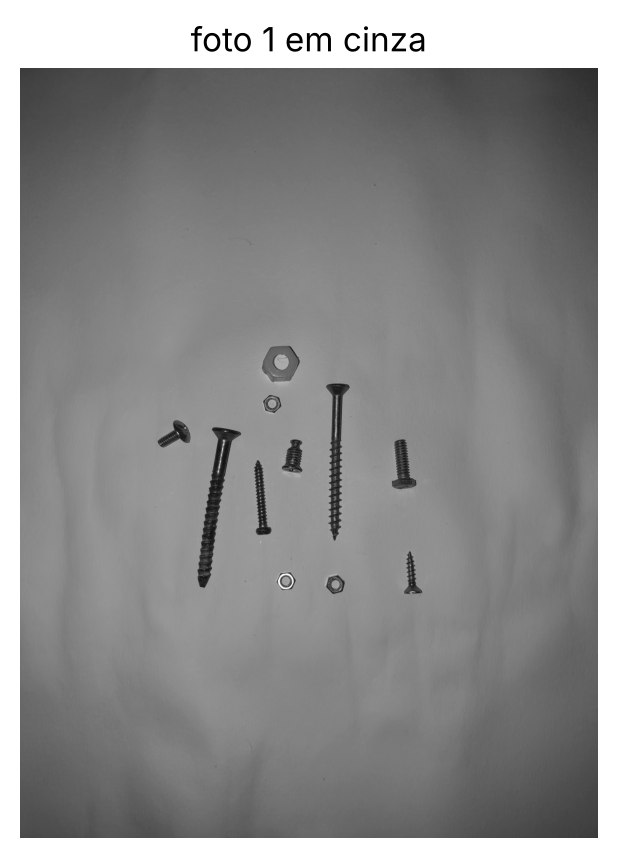

In [3]:
cor = cv2.imread(PASTA + fotos[0])
img = cv2.cvtColor(cor, cv2.COLOR_BGR2GRAY)
print('tamanho original:', img.shape)
esc = LARGURA / img.shape[1]
img = cv2.resize(img, None, fx=esc, fy=esc, interpolation=cv2.INTER_AREA)
print('tamanho novo:', img.shape)
mostrar(img, titulos=['foto 1 em cinza'])

## Etapa 2 · Suavizar (gaussiano 5×5)
Tira o ruído do sensor e a textura do papel antes do limiar, senão eles viram pontinhos na máscara. O PSNR mostra que a imagem mudou pouco (só o ruído).

PSNR original x suavizada = 41.8 dB


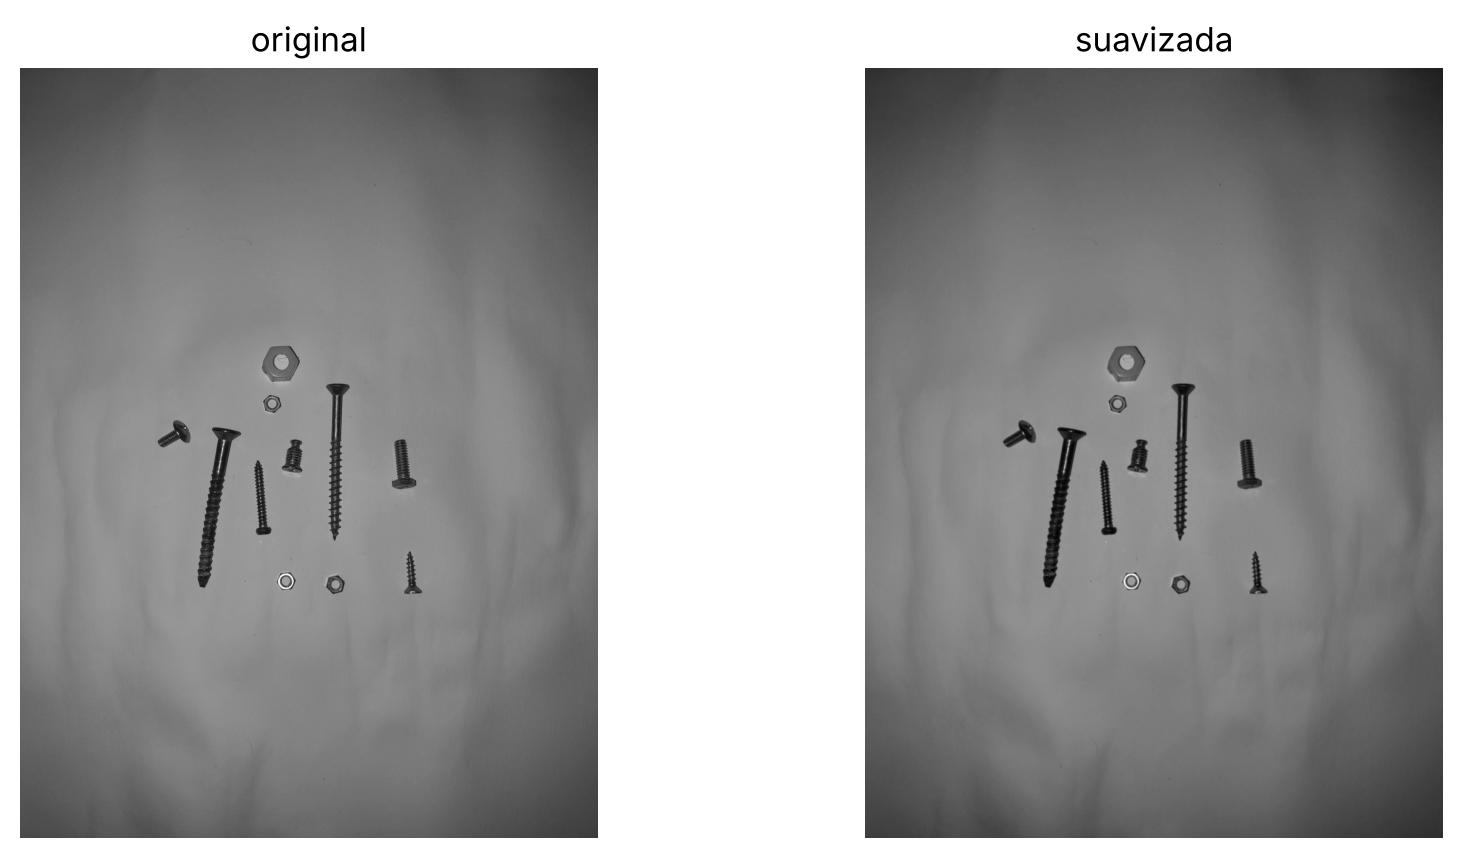

In [4]:
g = cv2.GaussianBlur(img, (5, 5), 0)
print('PSNR original x suavizada = %.1f dB' % cv2.PSNR(img, g))
mostrar(img, g, titulos=['original', 'suavizada'])

## Etapa 3 · Dividir pelo fundo
Pelo modelo f = i·r, o flash deixa o meio da foto claro e os cantos escuros (iluminação i diferente). Testamos Otsu direto e os cantos viravam objeto. O fundo é estimado com um fechamento de EE grande: como as peças são escuras e finas, o fechamento apaga elas e sobra só o papel. Dividindo a foto pelo fundo, a iluminação cancela e o papel fica com o mesmo nível na foto toda.

fundo: mínimo = 73  máximo = 253
desvio padrão do papel antes = 20.9, depois = 3.1


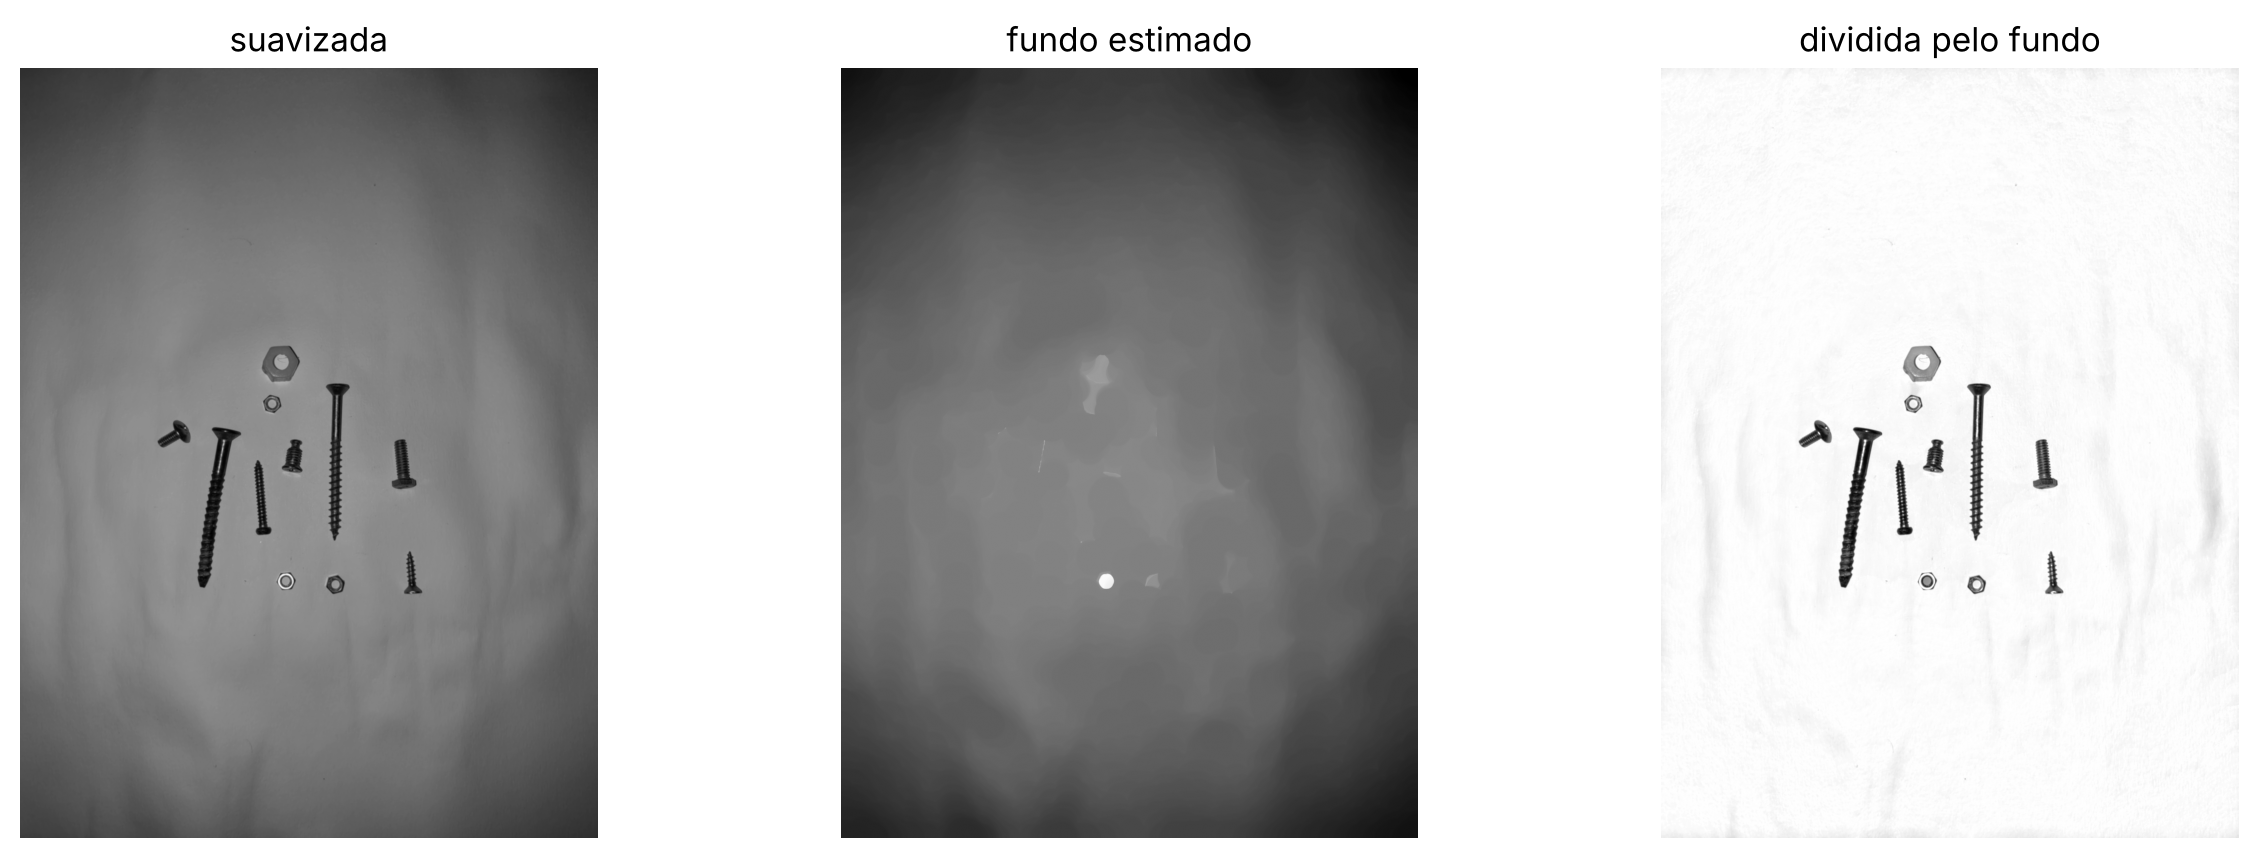

In [5]:
fundo = cv2.morphologyEx(g, cv2.MORPH_CLOSE, ee(K_FUNDO))
r = cv2.divide(g, fundo, scale=255)
print('fundo: mínimo =', fundo.min(), ' máximo =', fundo.max())
print('desvio padrão do papel antes = %.1f, depois = %.1f' % (g[fundo > 0].std(), r[r > 200].std()))
mostrar(g, fundo, r, titulos=['suavizada', 'fundo estimado', 'dividida pelo fundo'])

## Etapa 4 · Limiar de Otsu (invertido)
As peças são mais escuras que o papel, então usei THRESH_BINARY_INV pra peça ficar branca (a morfologia e a contagem tratam o branco como objeto). Depois da divisão o fundo é uniforme e o histograma tem dois morros, então o Otsu acha o T no vale.

Otsu sem dividir: T = 130.0 -> objetos = 238
Otsu dividido:    T = 186.0 -> objetos = 17


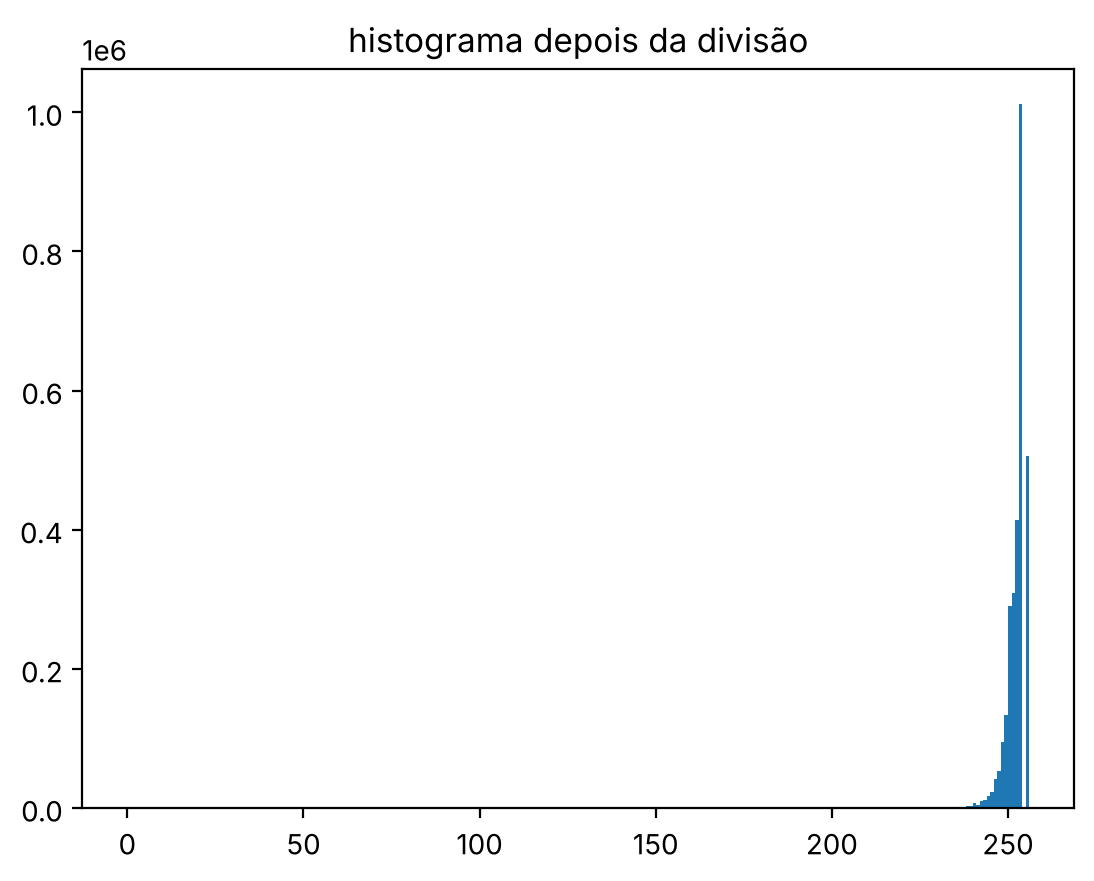

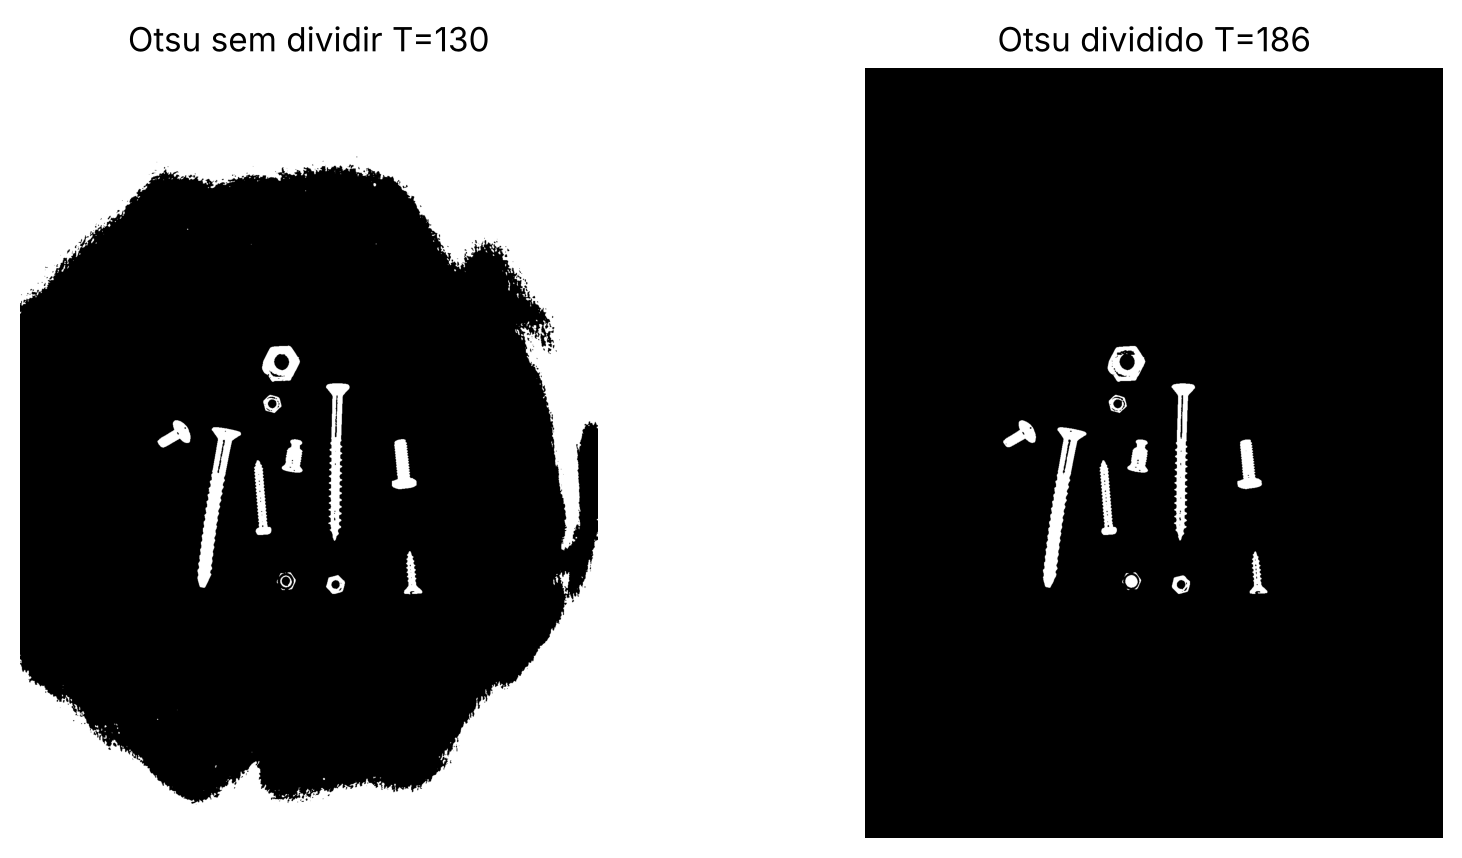

In [6]:
T0, m0 = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
T, m = cv2.threshold(r, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print('Otsu sem dividir: T =', T0, '-> objetos =', n_objetos(m0))
print('Otsu dividido:    T =', T, '-> objetos =', n_objetos(m))
plt.hist(r.ravel(), bins=256, range=(0, 256)); plt.title('histograma depois da divisão'); plt.show()
mostrar(m0, m, titulos=[f'Otsu sem dividir T={T0:.0f}', f'Otsu dividido T={T:.0f}'])

## Etapa 5 · Abertura
Apaga os pontinhos que sobraram do limiar (sujeira, textura). O EE é pequeno (3) porque as porcas pequenas aparecem como um anel fino e um EE maior apagava elas.

objetos antes da abertura = 17
objetos depois da abertura = 17


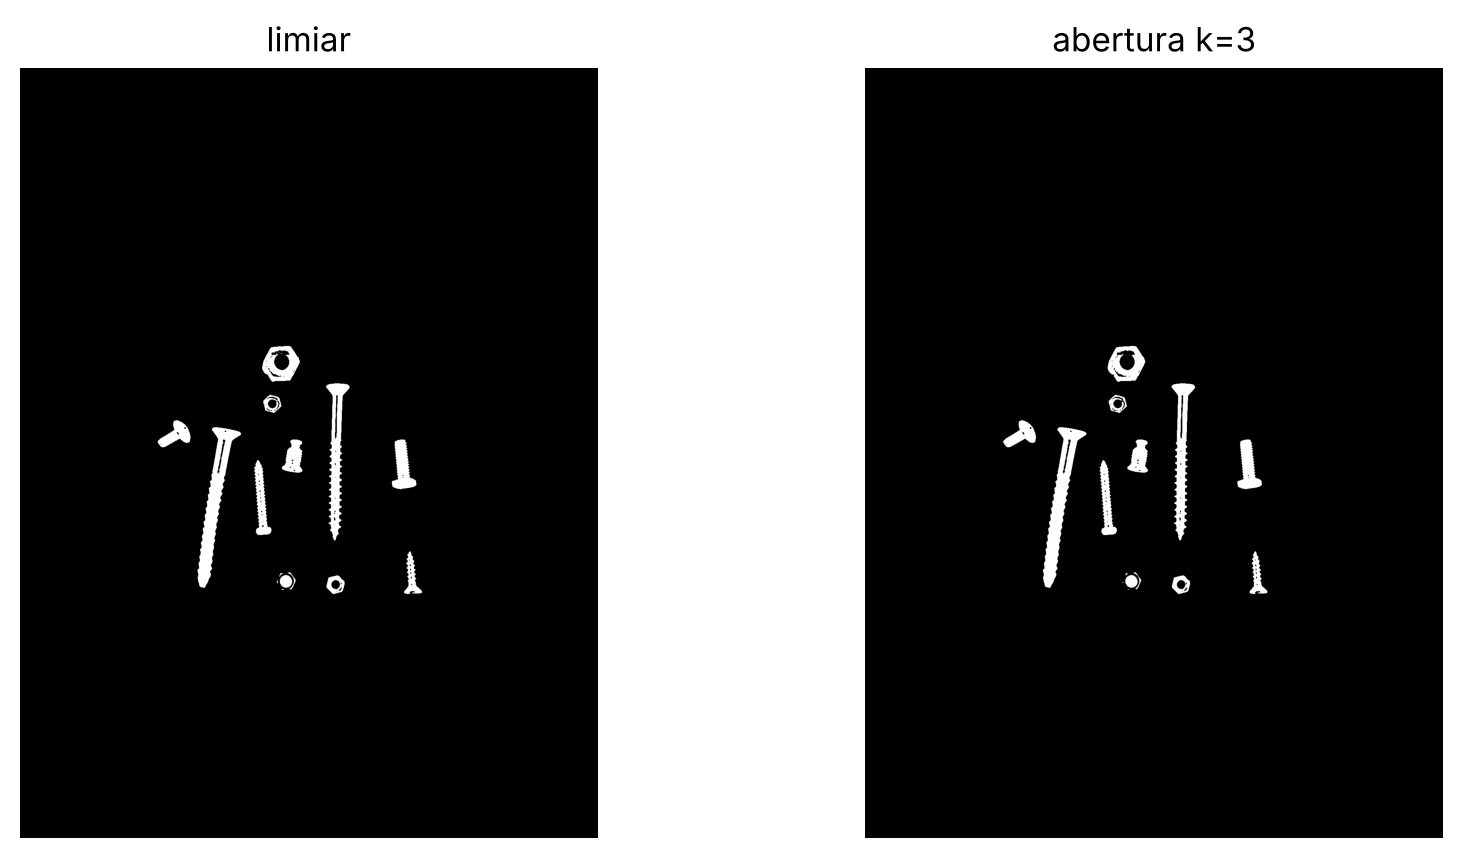

In [7]:
ab = cv2.morphologyEx(m, cv2.MORPH_OPEN, ee(K_AB))
print('objetos antes da abertura =', n_objetos(m))
print('objetos depois da abertura =', n_objetos(ab))
mostrar(m, ab, titulos=['limiar', f'abertura k={K_AB}'])

## Etapa 6 · Fechamento
O reflexo do metal fica claro como o papel e quebra a peça em pedaços (principalmente a rosca e o anel das porcas pequenas). O fechamento junta os pedaços de volta.

objetos antes do fechamento = 17
objetos depois do fechamento = 14


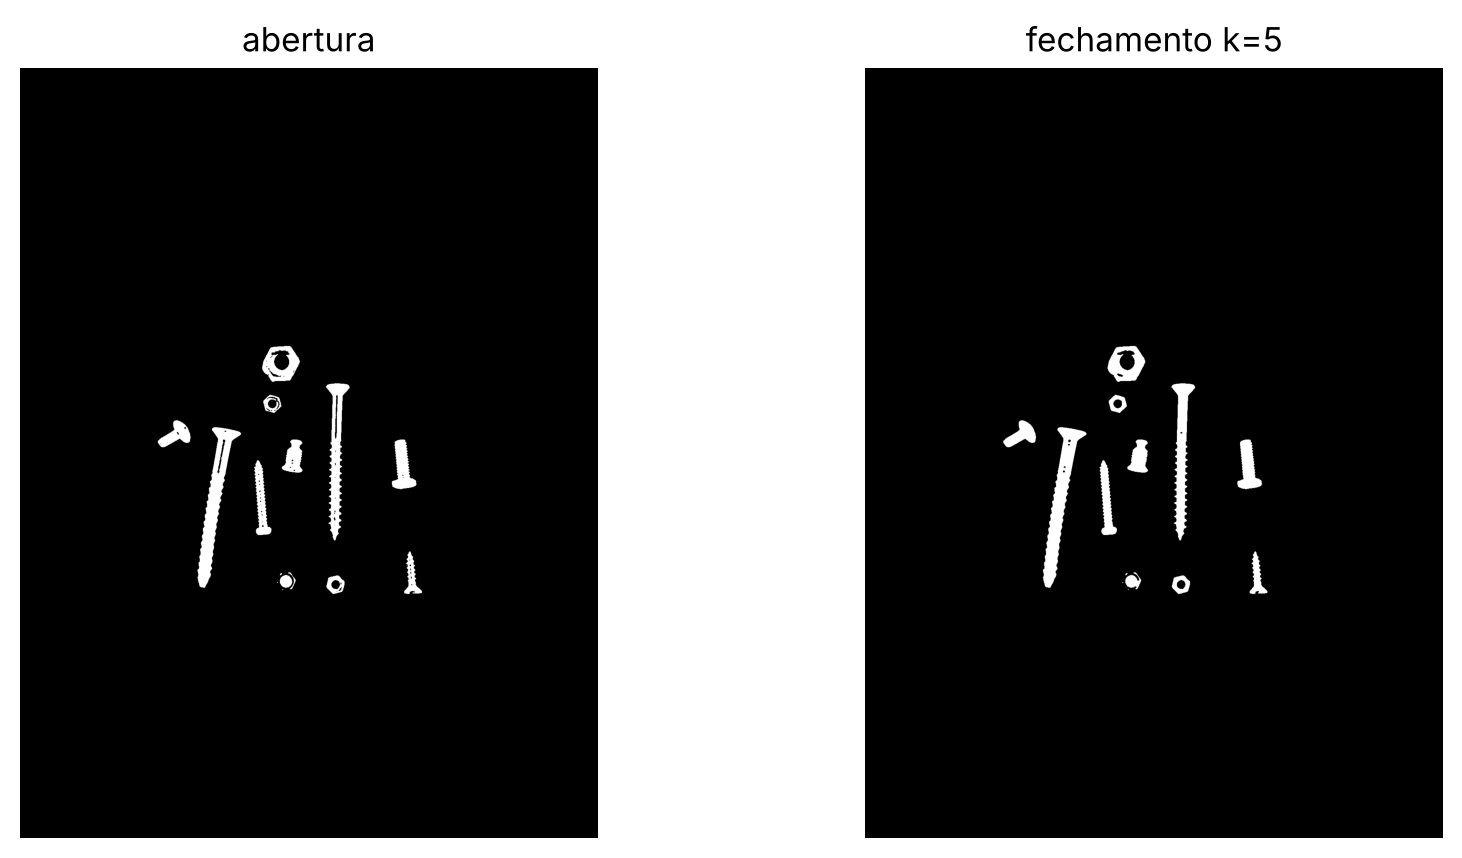

In [8]:
fe = cv2.morphologyEx(ab, cv2.MORPH_CLOSE, ee(K_FE))
print('objetos antes do fechamento =', n_objetos(ab))
print('objetos depois do fechamento =', n_objetos(fe))
mostrar(ab, fe, titulos=['abertura', f'fechamento k={K_FE}'])

## Etapa 7 · Preencher os furos
A porca aparece como um anel (o furo do meio fica preto). Pra medir a forma dela como um hexágono cheio, os furos são preenchidos: tudo o que é fundo e não está ligado à borda da imagem é furo (preenchimento por inundação a partir do canto).

pixels brancos antes = 50753  depois = 53368


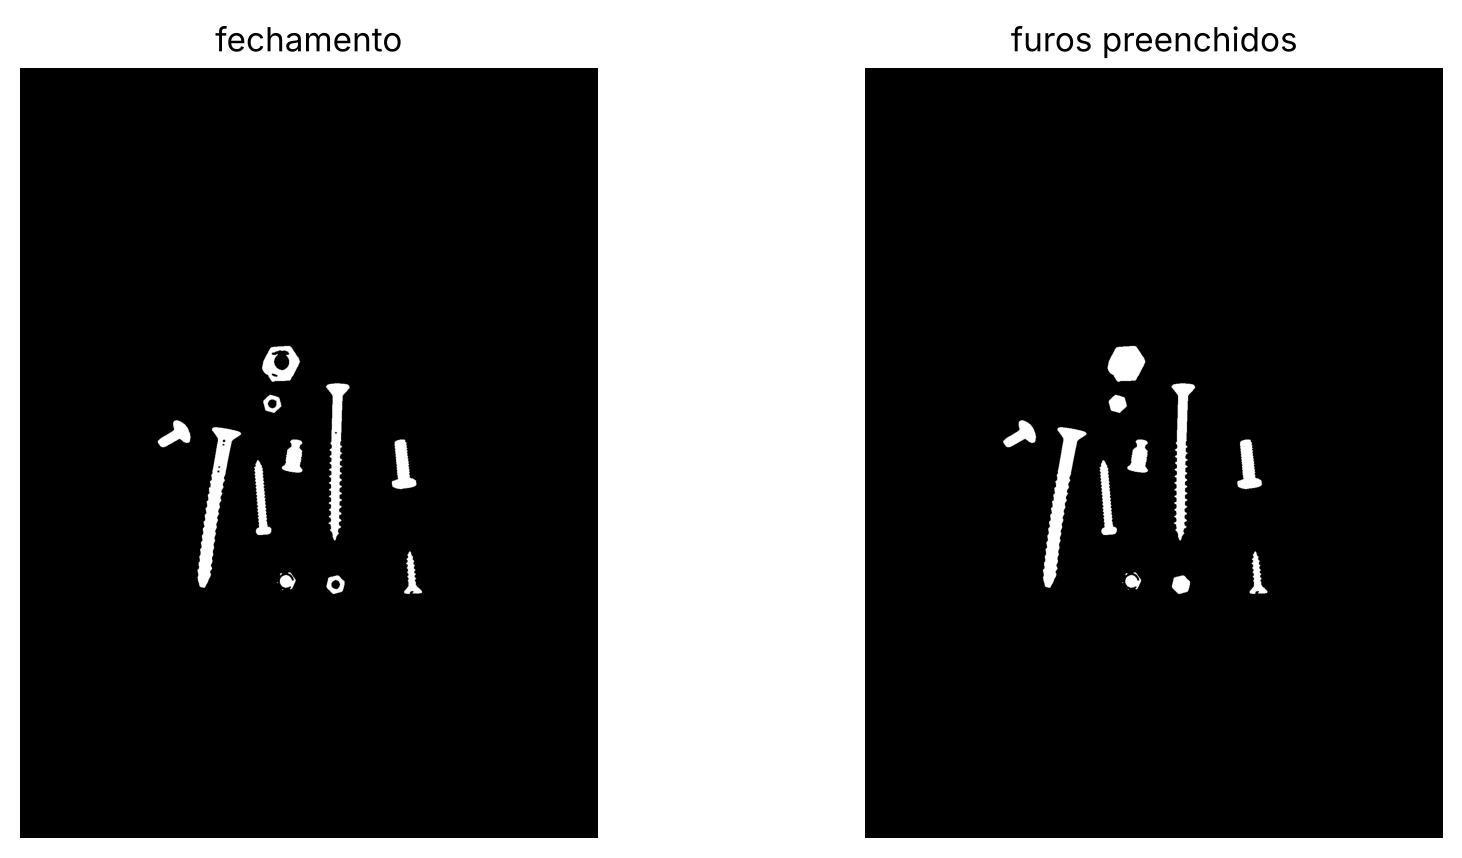

In [9]:
def preencher(m):
    mp = cv2.copyMakeBorder(m, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)   # garante que o canto é fundo
    cheia = mp.copy()
    aux = np.zeros((mp.shape[0] + 2, mp.shape[1] + 2), np.uint8)
    cv2.floodFill(cheia, aux, (0, 0), 255)      # todo fundo ligado à borda vira branco
    furos = cv2.bitwise_not(cheia)[1:-1, 1:-1]  # o que sobrou preto é furo
    return cv2.bitwise_or(m, furos)

pr = preencher(fe)
print('pixels brancos antes =', np.count_nonzero(fe), ' depois =', np.count_nonzero(pr))
mostrar(fe, pr, titulos=['fechamento', 'furos preenchidos'])

## Etapa 8 · Componentes conexos (N8) + filtro de área e de borda
Rotula cada peça. O que é menor que AREA_MIN é fragmento (sujeira, pedaço de brilho) e não conta. O que encosta na borda da foto também não conta: é a mesa aparecendo fora do papel ou peça cortada.

In [10]:
def pecas(m):
    n, rot, est, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    H, W = m.shape
    lista = []
    for i in range(1, n):
        x, y, w, h, a = est[i]
        if a < AREA_MIN:
            continue
        if x == 0 or y == 0 or x + w == W or y + h == H:
            continue
        lista.append((x, y, w, h, a))
    return n - 1, lista

n_total, lista = pecas(pr)
print('componentes antes do filtro =', n_total)
print('área mínima aceita =', AREA_MIN)
print('peças depois do filtro =', len(lista))

componentes antes do filtro = 14
área mínima aceita = 300
peças depois do filtro = 11


## Etapa 9 · Classificar pela forma
Vista de cima, a porca é um hexágono: a caixa em volta dela é quase quadrada (largura/altura perto de 1) e ela ocupa mais da metade da caixa. O parafuso é comprido, então a caixa é retangular ou, se ele estiver na diagonal, fica quase vazia. Usamos só largura, altura e área, que já vêm do connectedComponentsWithStats.

Primeiro tentamos pelo furo da porca, mas o brilho no corpo dos parafusos compridos também aparecia como furo e eles viravam porca.

largura/altura = 1.05   ocupa = 0.75
largura/altura = 0.15   ocupa = 0.43
largura/altura = 1.00   ocupa = 0.72
largura/altura = 1.21   ocupa = 0.51
largura/altura = 0.27   ocupa = 0.31
largura/altura = 0.63   ocupa = 0.67
largura/altura = 0.50   ocupa = 0.55
largura/altura = 0.23   ocupa = 0.48
largura/altura = 0.41   ocupa = 0.42
largura/altura = 0.93   ocupa = 0.58
largura/altura = 0.98   ocupa = 0.76
parafusos = 7 | porcas = 4


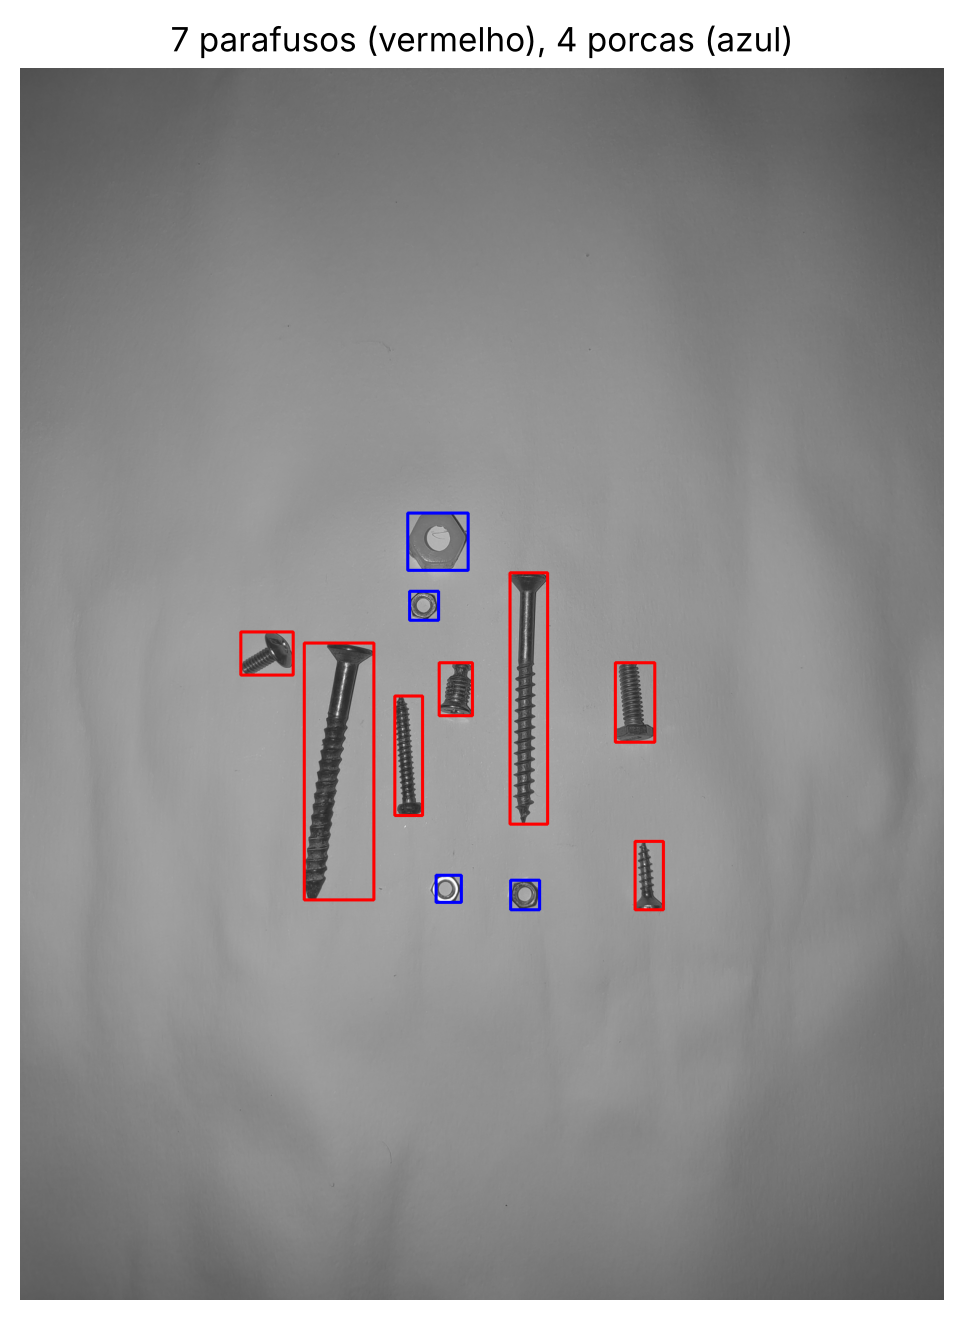

In [11]:
def classificar(lista, img):
    vis = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    parafusos, porcas = 0, 0
    for x, y, w, h, a in lista:
        razao = w / h               # 1 = caixa quadrada
        ocupa = a / (w * h)         # quanto da caixa a peça preenche
        if 0.8 <= razao <= 1.25 and ocupa >= 0.55:
            porcas += 1
            cv2.rectangle(vis, (x, y), (x+w, y+h), (0, 0, 255), 3)   # azul = porca
        else:
            parafusos += 1
            cv2.rectangle(vis, (x, y), (x+w, y+h), (255, 0, 0), 3)   # vermelho = parafuso
    return parafusos, porcas, vis

for x, y, w, h, a in lista:
    print('largura/altura = %.2f   ocupa = %.2f' % (w / h, a / (w * h)))
par, por, vis = classificar(lista, img)
print('parafusos =', par, '| porcas =', por)
mostrar(vis, titulos=[f'{par} parafusos (vermelho), {por} porcas (azul)'], tam=8)

## Pipeline completo
Junta as etapas numa função pra rodar em todas as fotos.

In [12]:
def pipeline(caminho):
    img = cv2.imread(caminho, cv2.IMREAD_GRAYSCALE)
    esc = LARGURA / img.shape[1]
    img = cv2.resize(img, None, fx=esc, fy=esc, interpolation=cv2.INTER_AREA)
    g = cv2.GaussianBlur(img, (5, 5), 0)
    fundo = cv2.morphologyEx(g, cv2.MORPH_CLOSE, ee(K_FUNDO))
    r = cv2.divide(g, fundo, scale=255)
    T, m = cv2.threshold(r, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, ee(K_AB))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, ee(K_FE))
    m = preencher(m)
    _, lista = pecas(m)
    par, por, vis = classificar(lista, img)
    return T, par, por, m, vis

## Resultados em todas as fotos
Erro = sistema − referência. A % é sobre a referência.

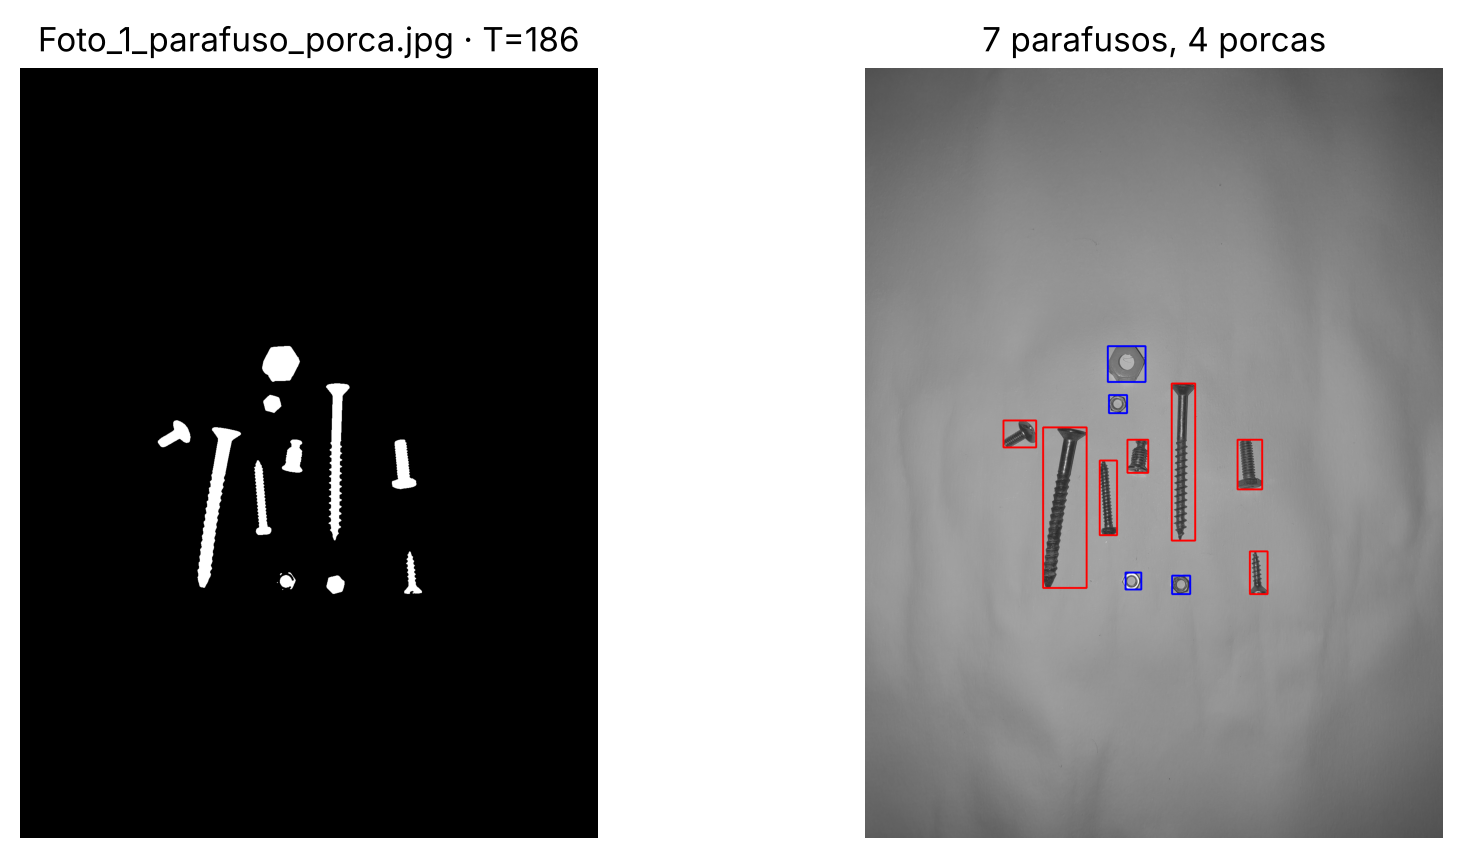

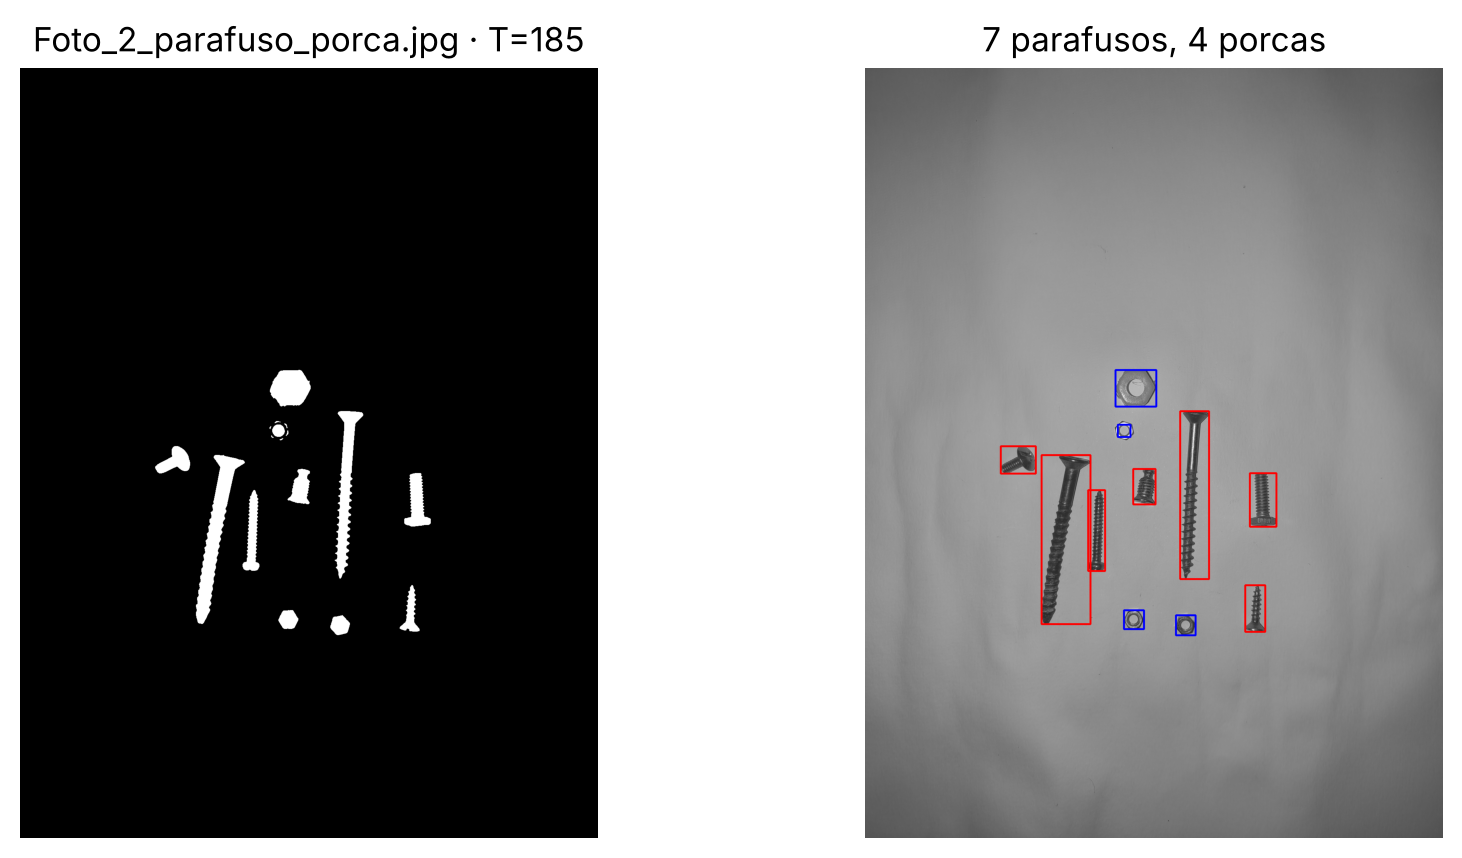

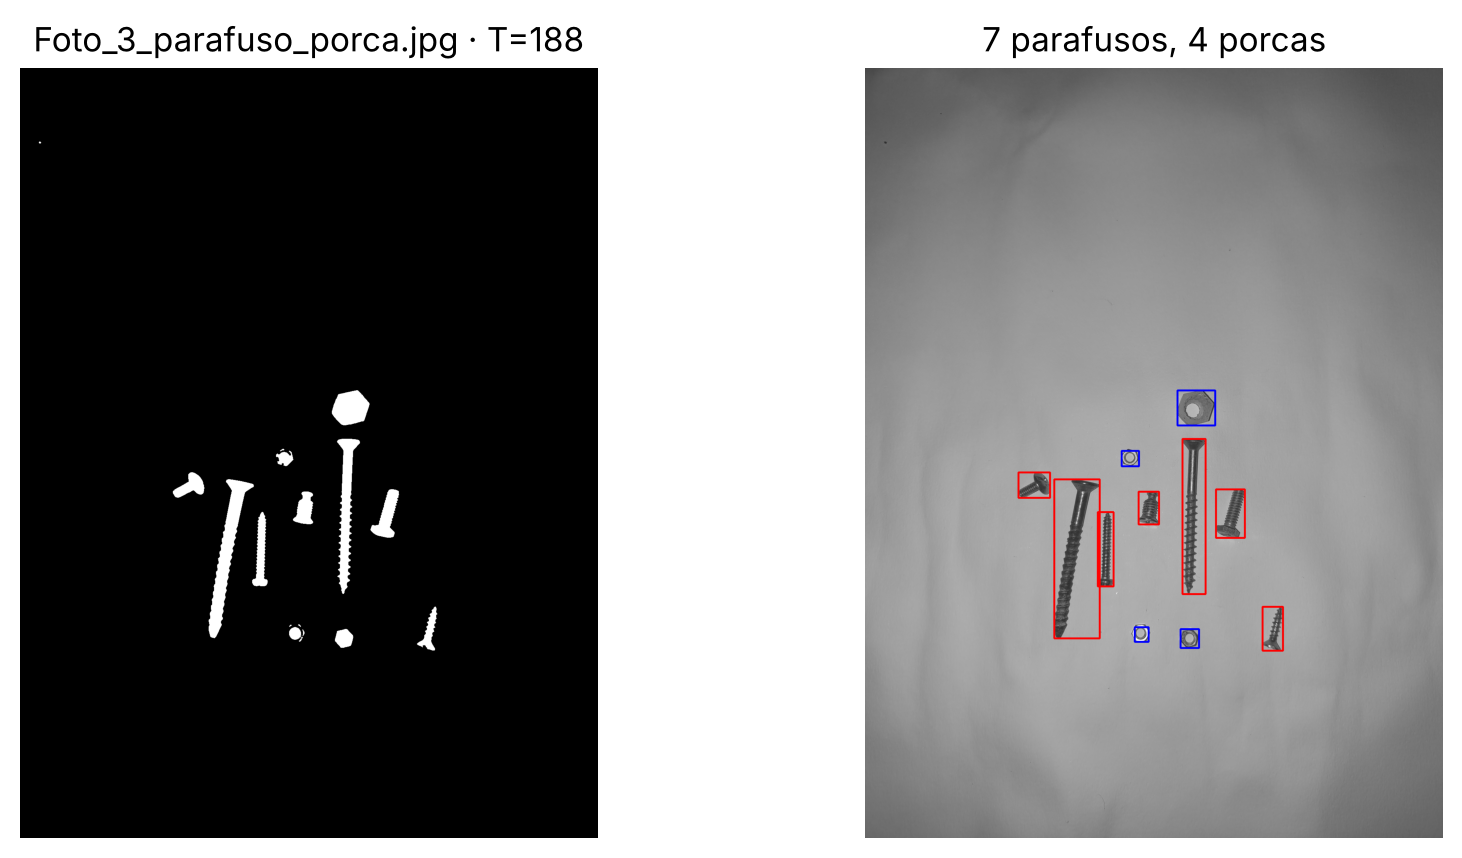

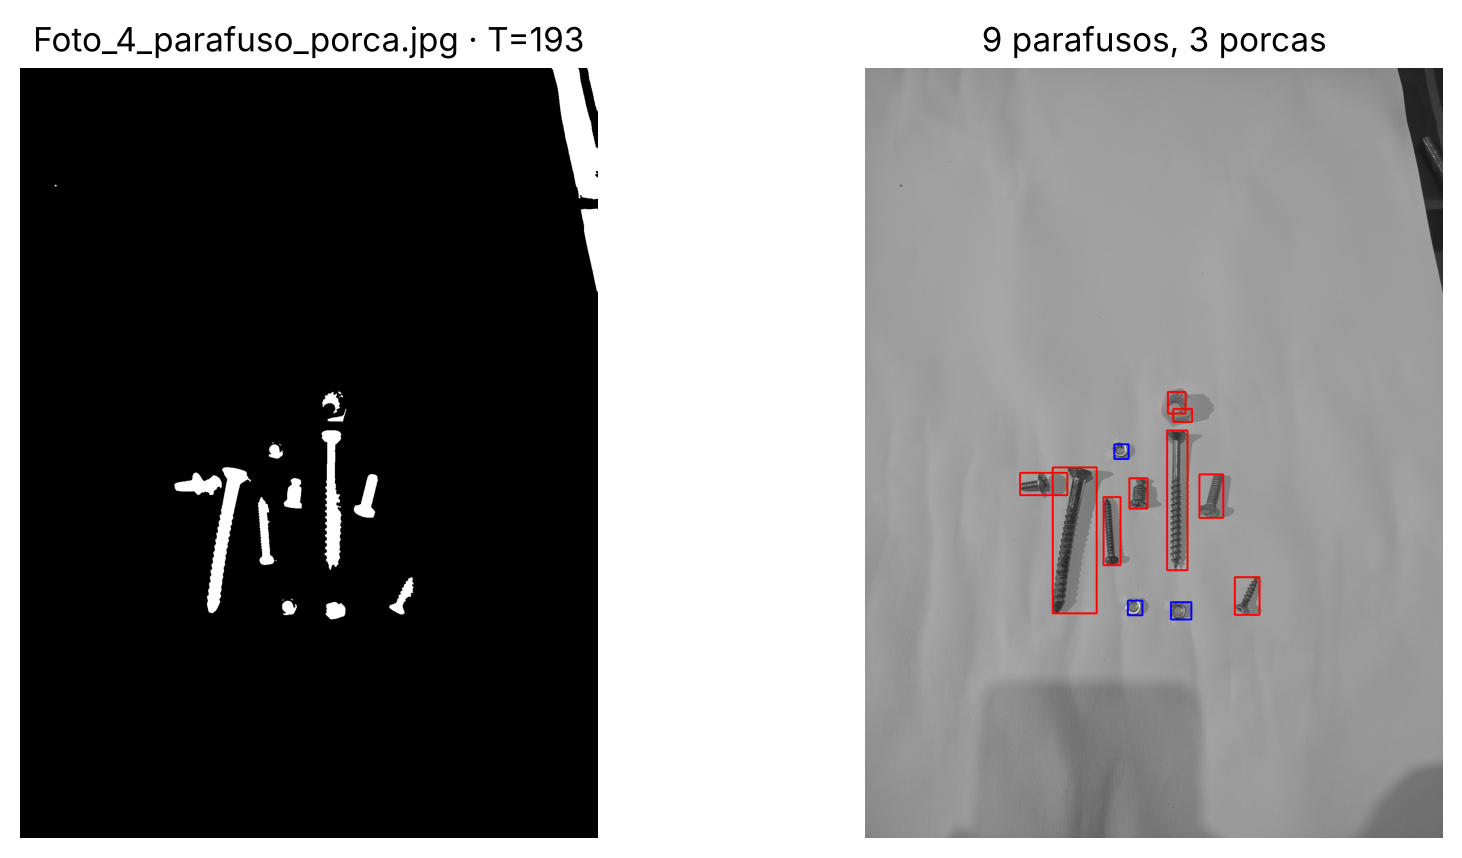

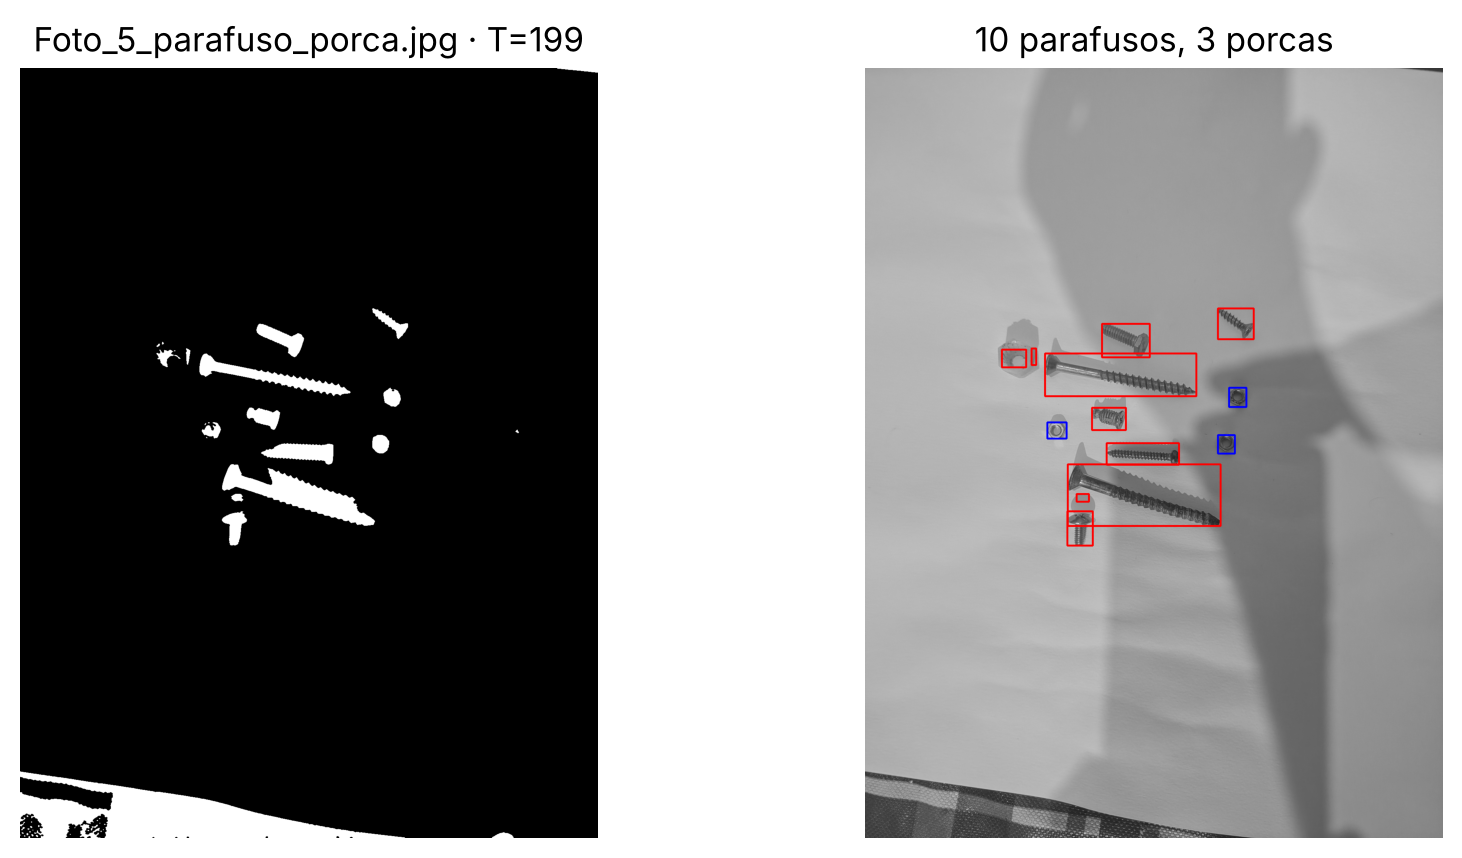

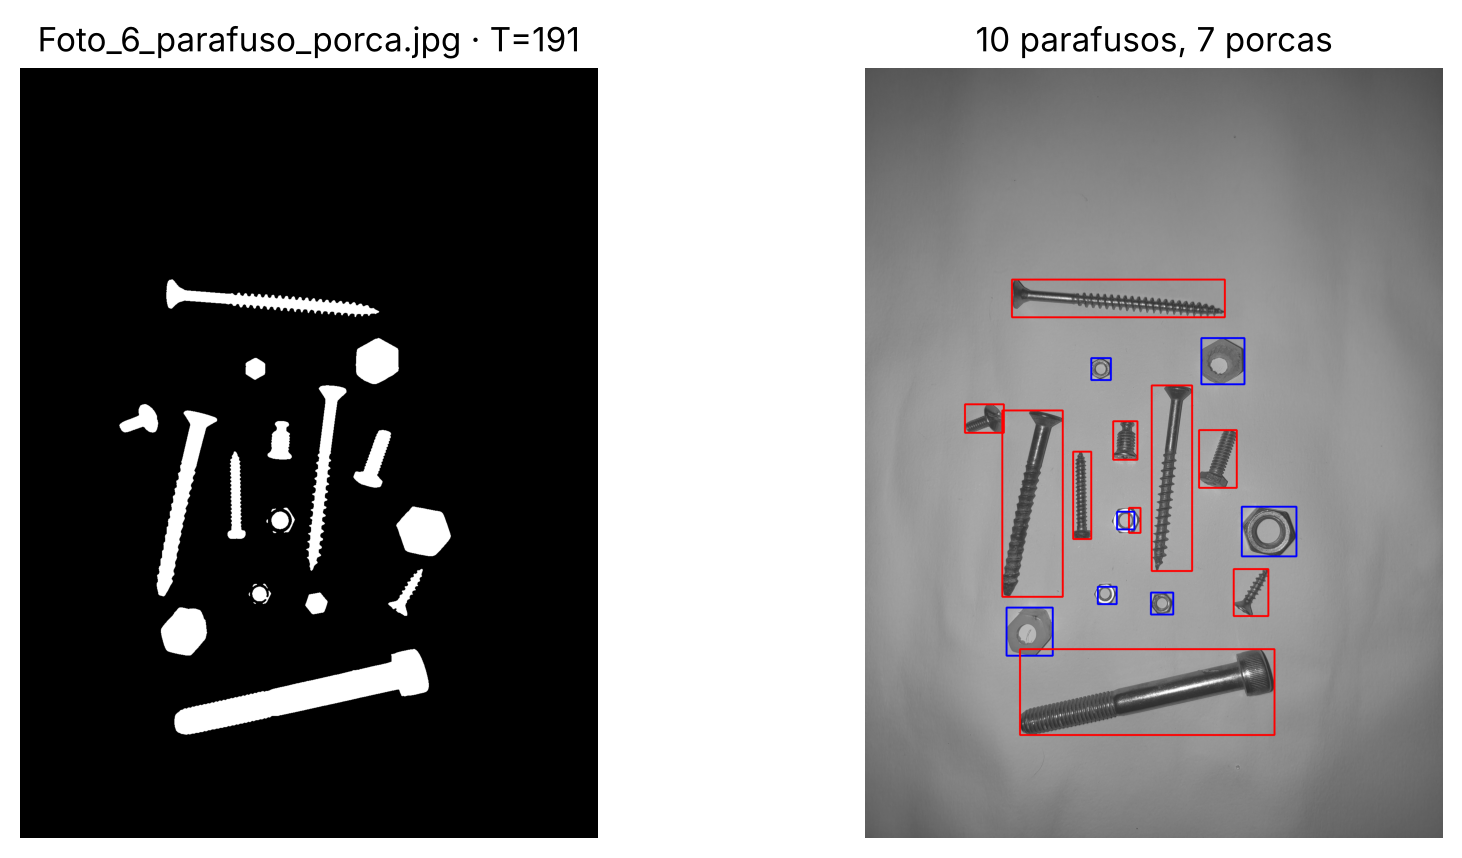

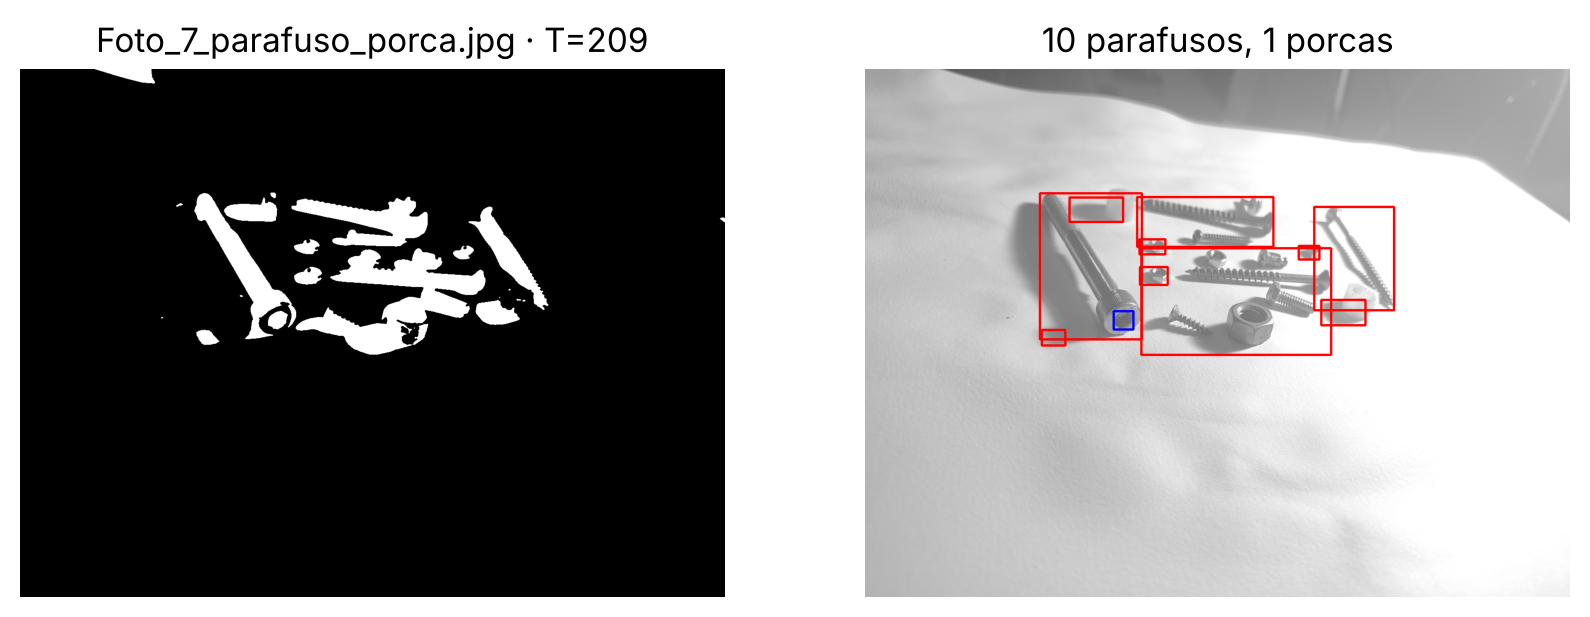

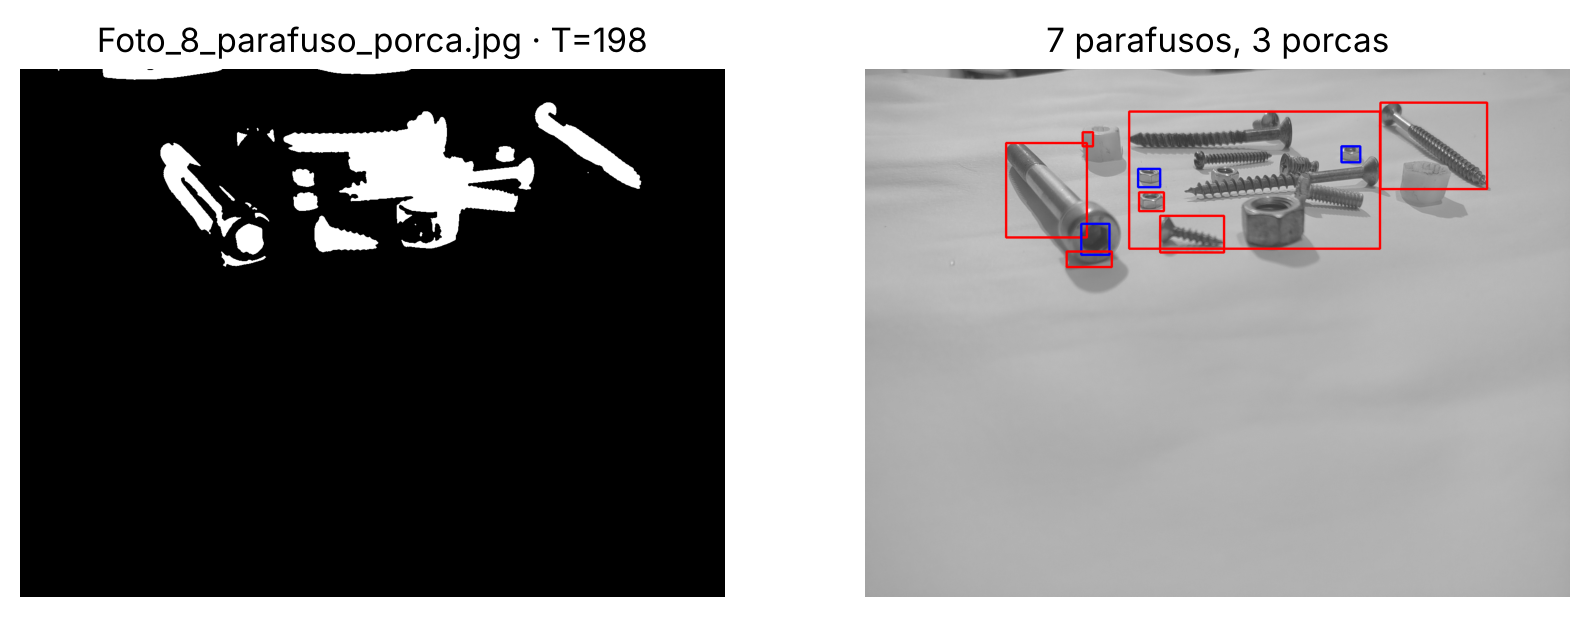

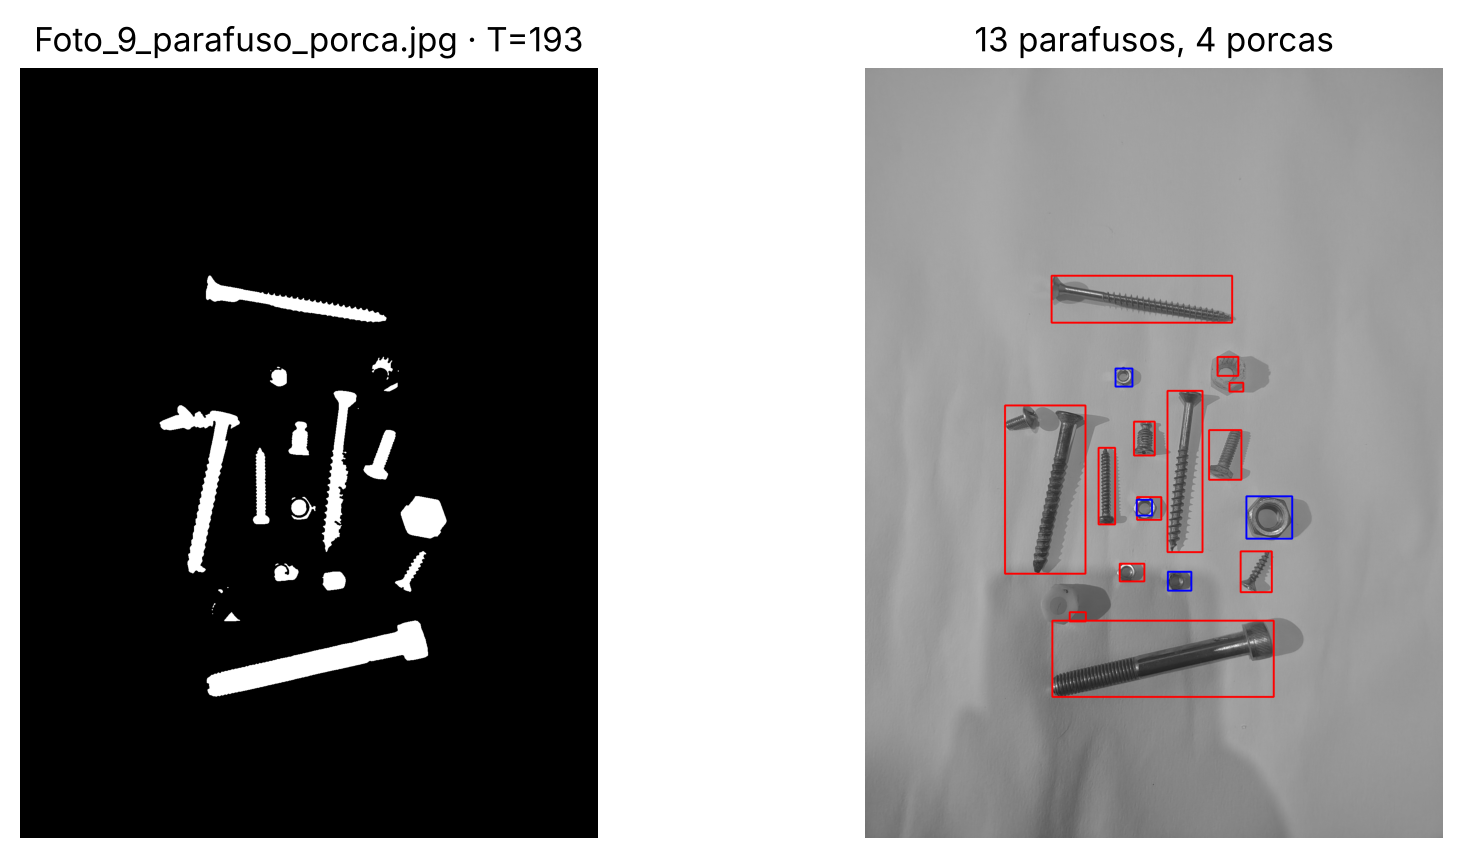

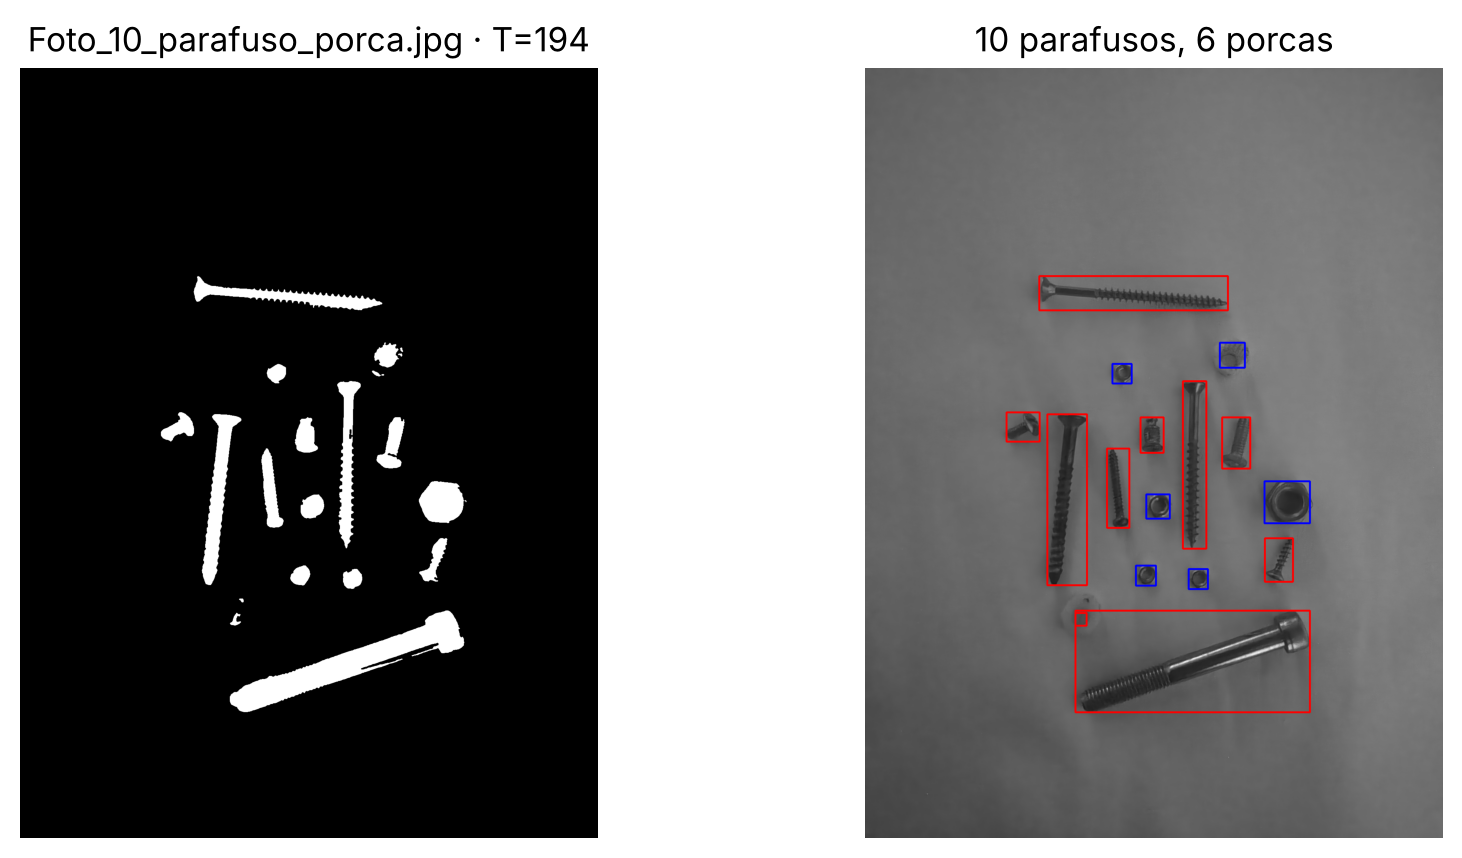

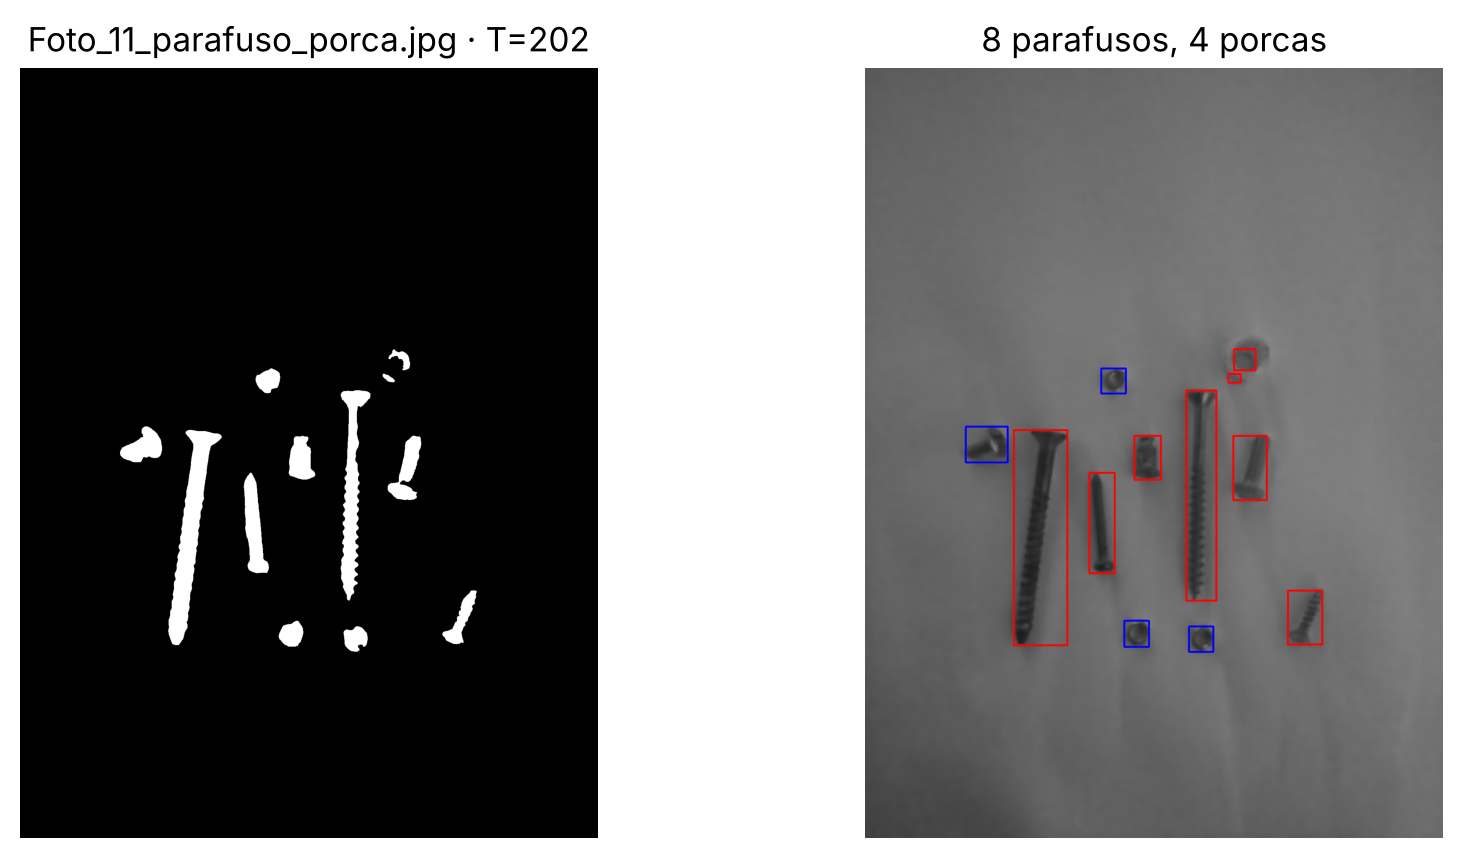

foto                           T | par ref par sis         erro | porca ref porca sis         erro
Foto_1_parafuso_porca.jpg    186 |       7       7    +0 (0.0%) |         4         4    +0 (0.0%)
Foto_2_parafuso_porca.jpg    185 |       7       7    +0 (0.0%) |         4         4    +0 (0.0%)
Foto_3_parafuso_porca.jpg    188 |       7       7    +0 (0.0%) |         4         4    +0 (0.0%)
Foto_4_parafuso_porca.jpg    193 |       7       9   +2 (28.6%) |         4         3   -1 (25.0%)
Foto_5_parafuso_porca.jpg    199 |       7      10   +3 (42.9%) |         4         3   -1 (25.0%)
Foto_6_parafuso_porca.jpg    191 |       9      10   +1 (11.1%) |         7         7    +0 (0.0%)
Foto_7_parafuso_porca.jpg    209 |       9      10   +1 (11.1%) |         7         1   -6 (85.7%)
Foto_8_parafuso_porca.jpg    198 |       9       7   -2 (22.2%) |         7         3   -4 (57.1%)
Foto_9_parafuso_porca.jpg    193 |       9      13   +4 (44.4%) |         7         4   -3 (42.9%)
Foto_10_pa

In [13]:
def erro(s, r):
    e = s - r
    return f'{e:+d} ({100 * abs(e) / r:.1f}%)'

linhas = []
for f in fotos:
    T, par, por, m, vis = pipeline(PASTA + f)
    rp, rq = referencia[f]
    linhas.append((f, T, rp, par, rq, por))
    mostrar(m, vis, titulos=[f'{f} · T={T:.0f}', f'{par} parafusos, {por} porcas'])

print(f"{'foto':<27} {'T':>4} | {'par ref':>7} {'par sis':>7} {'erro':>12} | {'porca ref':>9} {'porca sis':>9} {'erro':>12}")
for f, T, rp, par, rq, por in linhas:
    print(f"{f:<27} {T:>4.0f} | {rp:>7} {par:>7} {erro(par, rp):>12} | {rq:>9} {por:>9} {erro(por, rq):>12}")

## Onde o sistema falha
Resultado: as fotos 1, 2 e 3 (de cima, com flash) acertam tudo. A 6 erra só 1 peça e a 10 e a 11 erram 1 ou 2. As que mais erram são as inclinadas (7 e 8) e as com sombra forte (5 e 9).

- **Porca de plástico branca no papel branco:** ela quase não tem contraste. No limiar só aparece a borda ou a sombra dela, que quebra em pedaços compridos e vira "parafuso" (fotos 4, 9, 10 e 11). É a falha que mais aparece.
- **Sombra da mão (fotos 5 e 9):** a sombra é escura e grande, e a divisão pelo fundo não tira tudo. Pedaços da sombra grudam nas peças e aparecem peças a mais.
- **Foto inclinada (fotos 7 e 8):** a sombra de cada peça fica comprida e gruda na vizinha, então várias peças viram um objeto só. A porca vista de lado não é um hexágono e o critério de forma não funciona.
- **Brilho do metal:** o pino do meio e algumas porcas pequenas às vezes quebram em dois pedaços (foto 6).
- **Parafuso curto:** o parafuso pequeno de cabeça redonda tem a caixa quase quadrada e já foi confundido com porca (foto 11).

